# W6 — Environmental Statistics

**Research question:** How is relative humidity (RH) related to air temperature (AMB_TEMP) in the Taiwan environmental dataset?

**Workflow:** Describe → Estimate → Associate → Diagnose → Interpret → Commit.

This notebook continues the Assignment 5 QA/QC-processed dataset.

**Caution:** Statistical association does not imply causation. Temporal dependence may affect uncertainty estimates.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUTCOME = 'RH'
PREDICTOR = 'AMB_TEMP'
N_BOOT = 4000
SEED = 42

# Cek apakah file dataset ada di Colab
matches = list(Path('/content').rglob('analysis_ready_temperature_humidity (1).csv'))

print("Files found:", len(matches))

for m in matches:
    print(m)

Files found: 1
/content/analysis_ready_temperature_humidity (1).csv


In [ ]:
DATA_FILE = matches[0]

raw = pd.read_csv(DATA_FILE)
x = raw.copy()

x['monitordate'] = pd.to_datetime(x['monitordate'], errors='coerce')
x[OUTCOME] = pd.to_numeric(x[OUTCOME], errors='coerce')
x[PREDICTOR] = pd.to_numeric(x[PREDICTOR], errors='coerce')

x = x.sort_values('monitordate').reset_index(drop=True)

print("Rows:", len(x))
print("Valid RH:", x[OUTCOME].count())
print("Valid AMB_TEMP:", x[PREDICTOR].count())

x.head()

Rows: 476
Valid RH: 476
Valid AMB_TEMP: 476


,siteid,sitename,county,monitordate,AMB_TEMP,RH
0,34,線西,彰化縣,2026-10-14 14:00:00,29.5,59
1,10,淡水,新北市,2026-10-14 14:00:00,27.8,55
2,35,二林,彰化縣,2026-10-14 14:00:00,30.4,58
3,1,基隆,基隆市,2026-10-14 15:00:00,27.4,65
4,22,湖口,新竹縣,2026-10-14 15:00:00,29.0,48


,Metric,Value
0,N valid,476.000
1,Mean,64.838
2,Median,65.000
3,SD,9.152
4,Q1,59.000
5,Q3,71.000
6,IQR,12.000
7,Min,36.000
8,Max,95.000


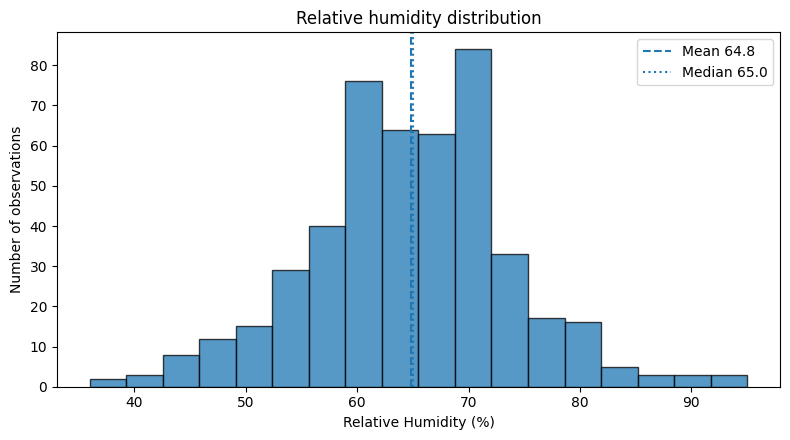

In [ ]:
vals = x[OUTCOME].dropna()

summary = pd.DataFrame({
    'Metric': ['N valid','Mean','Median','SD','Q1','Q3','IQR','Min','Max'],
    'Value': [
        len(vals),
        vals.mean(),
        vals.median(),
        vals.std(ddof=1),
        vals.quantile(.25),
        vals.quantile(.75),
        vals.quantile(.75)-vals.quantile(.25),
        vals.min(),
        vals.max()
    ]
})

display(summary.round(3))

fig, ax = plt.subplots(figsize=(8,4.5))
ax.hist(vals, bins=18, edgecolor='black', alpha=.75)

ax.axvline(vals.mean(), linestyle='--', label=f'Mean {vals.mean():.1f}')
ax.axvline(vals.median(), linestyle=':', label=f'Median {vals.median():.1f}')

ax.set(
    xlabel='Relative Humidity (%)',
    ylabel='Number of observations',
    title='Relative humidity distribution'
)

ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR/'w6_rh_distribution.png', dpi=160)

plt.show()

Mean: 64.838 | IID bootstrap 95% interval: [64.006 65.658]


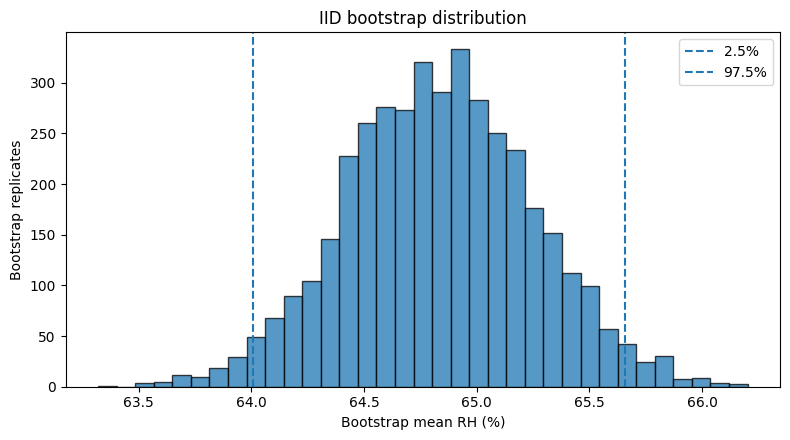

In [ ]:
rng = np.random.default_rng(SEED)

array = vals.to_numpy()

boot_iid = np.array([
    rng.choice(array, len(array), replace=True).mean()
    for _ in range(N_BOOT)
])

ci_iid = np.quantile(boot_iid, [.025, .975])

print(
    'Mean:',
    round(array.mean(), 3),
    '| IID bootstrap 95% interval:',
    np.round(ci_iid, 3)
)

fig, ax = plt.subplots(figsize=(8,4.5))

ax.hist(boot_iid, bins=35, edgecolor='black', alpha=.75)
ax.axvline(ci_iid[0], linestyle='--', label='2.5%')
ax.axvline(ci_iid[1], linestyle='--', label='97.5%')

ax.set(
    xlabel='Bootstrap mean RH (%)',
    ylabel='Bootstrap replicates',
    title='IID bootstrap distribution'
)

ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR/'w6_bootstrap_iid.png', dpi=160)

plt.show()

Lag-1 autocorrelation: 0.962


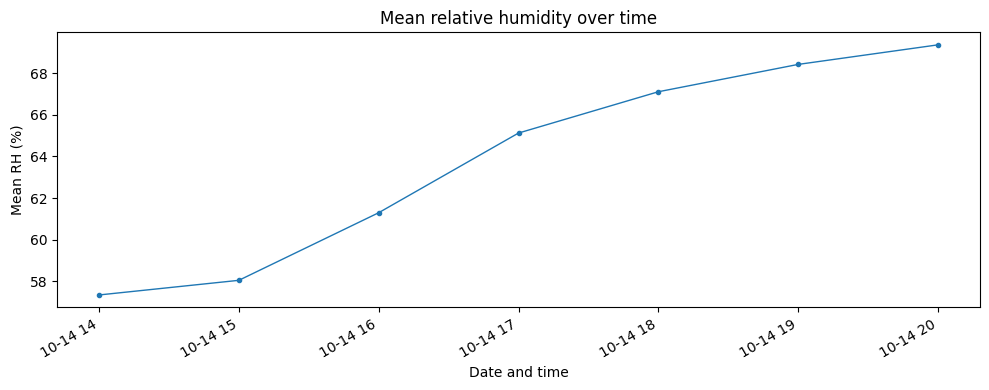

In [ ]:
ts = (
    x[['monitordate', OUTCOME]]
    .dropna()
    .groupby('monitordate', as_index=False)[OUTCOME]
    .mean()
    .sort_values('monitordate')
)

lag1 = ts[OUTCOME].autocorr(lag=1)

print('Lag-1 autocorrelation:', round(lag1, 3))

fig, ax = plt.subplots(figsize=(10,4))

ax.plot(
    ts['monitordate'],
    ts[OUTCOME],
    marker='.',
    linewidth=1
)

ax.set(
    xlabel='Date and time',
    ylabel='Mean RH (%)',
    title='Mean relative humidity over time'
)

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURES_DIR/'w6_rh_timeseries.png', dpi=160)

plt.show()

,Metric,Value
0,Paired N,476.000
1,Pearson r,-0.500
2,Spearman rho,-0.402


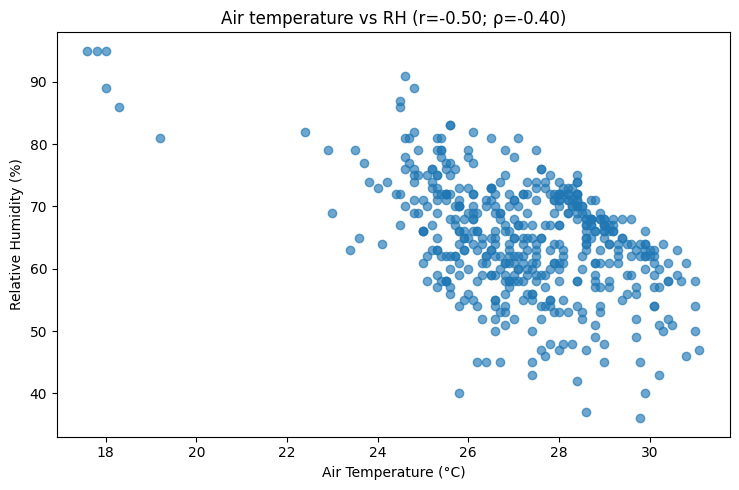

In [ ]:
pairs = x[[OUTCOME, PREDICTOR]].dropna()

pearson_r = pairs[OUTCOME].corr(
    pairs[PREDICTOR],
    method='pearson'
)

spearman_rho = pairs[OUTCOME].corr(
    pairs[PREDICTOR],
    method='spearman'
)

association = pd.DataFrame({
    'Metric': ['Paired N','Pearson r','Spearman rho'],
    'Value': [len(pairs), pearson_r, spearman_rho]
})

display(association.round(3))

fig, ax = plt.subplots(figsize=(7.5,5))

ax.scatter(
    pairs[PREDICTOR],
    pairs[OUTCOME],
    alpha=.65
)

ax.set(
    xlabel='Air Temperature (°C)',
    ylabel='Relative Humidity (%)',
    title=f'Air temperature vs RH (r={pearson_r:.2f}; ρ={spearman_rho:.2f})'
)

fig.tight_layout()
fig.savefig(FIGURES_DIR/'w6_temperature_vs_rh.png', dpi=160)

plt.show()

In [ ]:
q1 = x[OUTCOME].quantile(.25)
q3 = x[OUTCOME].quantile(.75)
iqr = q3 - q1

lower = q1 - 1.5*iqr
upper = q3 + 1.5*iqr

flag = (x[OUTCOME] < lower) | (x[OUTCOME] > upper)

alt = x.loc[
    ~flag,
    [OUTCOME, PREDICTOR]
].dropna()

sensitivity = pd.DataFrame([
    {
        'Scenario': 'All QA/QC-valid observations',
        'N': len(pairs),
        'Pearson_r': pearson_r,
        'Spearman_rho': spearman_rho
    },
    {
        'Scenario': 'IQR potential outliers excluded',
        'N': len(alt),
        'Pearson_r': alt[OUTCOME].corr(alt[PREDICTOR], method='pearson'),
        'Spearman_rho': alt[OUTCOME].corr(alt[PREDICTOR], method='spearman')
    }
])

display(sensitivity.round(3))

print('Potential outliers:', int(flag.sum()))

,Scenario,N,Pearson_r,Spearman_rho
0,All QA/QC-valid observations,476,-0.500,-0.402
1,IQR potential outliers excluded,468,-0.445,-0.383


Potential outliers: 8


## Interpretation

The mean relative humidity was approximately 64.84%, with an IID bootstrap 95% confidence interval of approximately 64.01–65.66%. Air temperature and relative humidity showed a moderate negative association (Pearson r = -0.500; Spearman ρ = -0.402). Excluding eight potential IQR outliers reduced the Pearson correlation to -0.445, but the negative association remained. Because the dataset covers only one calendar day and contains temporal dependence, the IID bootstrap uncertainty should be interpreted cautiously, and the association does not demonstrate causation.

In [ ]:
exports = {
    'w6_descriptive_statistics.csv': summary,
    'w6_correlations.csv': association,
    'w6_sensitivity.csv': sensitivity
}

for filename, table in exports.items():
    path = PROCESSED_DIR / filename
    table.to_csv(path, index=False)
    print('Saved:', path)

print('Figures in:', FIGURES_DIR)

Saved: /content/data/processed/w6_descriptive_statistics.csv
Saved: /content/data/processed/w6_correlations.csv
Saved: /content/data/processed/w6_sensitivity.csv
Figures in: /content/figures


In [ ]:
FIGURES_DIR = Path('/content/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(FIGURES_DIR)

/content/figures


In [ ]:
list(FIGURES_DIR.glob('*.png'))

[PosixPath('/content/figures/w6_bootstrap_iid.png'),
 PosixPath('/content/figures/w6_temperature_vs_rh.png'),
 PosixPath('/content/figures/w6_rh_timeseries.png'),
 PosixPath('/content/figures/w6_rh_distribution.png')]